<a href="https://colab.research.google.com/github/Mercedes1798/Python_Data_Analysis_Project/blob/main/Course_Project_%24_to_%E2%82%AC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

I've taken the data from Section II (skill vs pay) of the course project and made adjustments to show median salaries in euro.

In [1]:
# Import dataset and basic clean up

import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

README.md:   0%|          | 0.00/3.25k [00:00<?, ?B/s]

data_jobs.csv: reconstructing file:   0%|          |  0.00B /  231MB            

data_jobs.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/785741 [00:00<?, ? examples/s]

In [14]:
df_DA_DE = df[(df["job_title_short"] == "Data Analyst") & (df["job_country"] == "Germany")].copy()

df_DA_DE = df_DA_DE.dropna(subset=["salary_year_avg"])

#Convert salaries from $ to € with exchange rate as of 20.10.2026
df_DA_DE["salary_year_avg"] = ((df_DA_DE["salary_year_avg"]) * 0.89).astype(int)

df_DA_DE = df_DA_DE.explode("job_skills")

df_DA_DE.tail(5)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
770282,Data Analyst,Head of Data Analytics (F/M/X),"Munich, Germany",via Ai-Jobs.net,Full-time,False,Germany,2023-01-19 01:22:42,False,False,Germany,year,148113,NaN,PPRO,tableau,"{'analyst_tools': ['looker', 'tableau'], 'clou..."
770282,Data Analyst,Head of Data Analytics (F/M/X),"Munich, Germany",via Ai-Jobs.net,Full-time,False,Germany,2023-01-19 01:22:42,False,False,Germany,year,148113,NaN,PPRO,terraform,"{'analyst_tools': ['looker', 'tableau'], 'clou..."
781105,Data Analyst,Data Analyst,"Munich, Germany",via Ai-Jobs.net,Full-time,False,Germany,2023-04-05 06:34:08,False,False,Germany,year,98945,NaN,Lilium,python,"{'libraries': ['pyspark'], 'other': ['terminal..."
781105,Data Analyst,Data Analyst,"Munich, Germany",via Ai-Jobs.net,Full-time,False,Germany,2023-04-05 06:34:08,False,False,Germany,year,98945,NaN,Lilium,pyspark,"{'libraries': ['pyspark'], 'other': ['terminal..."
781105,Data Analyst,Data Analyst,"Munich, Germany",via Ai-Jobs.net,Full-time,False,Germany,2023-04-05 06:34:08,False,False,Germany,year,98945,NaN,Lilium,terminal,"{'libraries': ['pyspark'], 'other': ['terminal..."


In [15]:
df_DA_top_pay = df_DA_DE.groupby('job_skills')['salary_year_avg'].agg(['count', 'median']).sort_values(by='median', ascending=False)

df_DA_top_pay = df_DA_top_pay.head(5)

df_DA_top_pay

,count,median
job_skills,,
github,3,177710.0
bigquery,1,148113.0
nosql,1,148113.0
kafka,1,148113.0
redshift,1,148113.0


In [16]:
df_DA_skills = df_DA_DE.groupby('job_skills')['salary_year_avg'].agg(['count', 'median']).sort_values(by='count', ascending=False)

df_DA_skills = df_DA_skills.head(5).sort_values(by='median', ascending=False)

df_DA_skills

,count,median
job_skills,,
python,18,98945.0
excel,7,94028.0
sql,24,90335.0
tableau,13,89445.0
r,7,66810.0


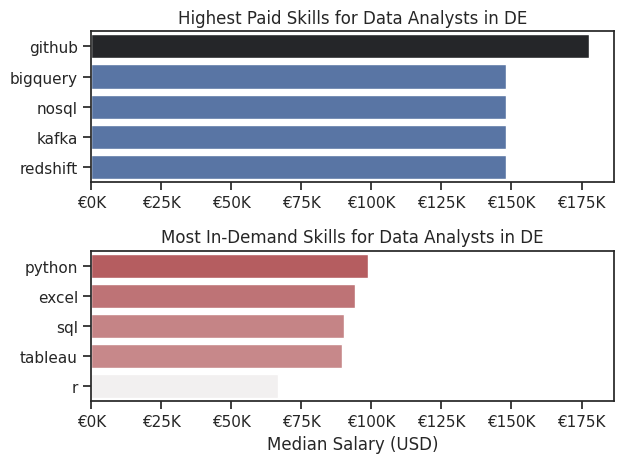

In [17]:
fig, ax = plt.subplots(2, 1)

# Highest Paid Skills
sns.barplot(data=df_DA_top_pay, x='median', y=df_DA_top_pay.index, hue='median', ax=ax[0], palette='dark:b_r')
ax[0].legend().remove()
# Using plt: df_DA_top_pay[::-1].plot(kind='barh', y='median', ax=ax[0], legend=False)
ax[0].set_title('Highest Paid Skills for Data Analysts in DE')
ax[0].set_ylabel('')
ax[0].set_xlabel('')
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'€{int(x/1000)}K'))


# Most In-Demand Skills
sns.barplot(data=df_DA_skills, x='median', y=df_DA_skills.index, hue='median', ax=ax[1], palette='light:r')
ax[1].legend().remove()
# Using plt: df_DA_skills[::-1].plot(kind='barh', y='median', ax=ax[1], legend=False)
ax[1].set_title('Most In-Demand Skills for Data Analysts in DE')
ax[1].set_ylabel('')
ax[1].set_xlabel('Median Salary (USD)')
ax[1].set_xlim(ax[0].get_xlim())  # Set the same x-axis limits as the first plot
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'€{int(x/1000)}K'))

sns.set_theme(style='ticks')
plt.tight_layout()
plt.show()